In [10]:
import numpy as np
import pandas as pd
from scipy import stats

%matplotlib inline
import matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

La varianza misura quanto ogni valore di una serie dista dalla media.
Noi calcoliamo la deviazione dalla media, eleviamo al quadrato per avere valori positivi e nefacciamo la media.

In [12]:
planets = sns.load_dataset('planets')
print('DataFrame size:', planets.shape)
planets.distance.describe()

DataFrame size: (1035, 6)


count     808.000000
mean      264.069282
std       733.116493
min         1.350000
25%        32.560000
50%        55.250000
75%       178.500000
max      8500.000000
Name: distance, dtype: float64

<Axes: xlabel='distance'>

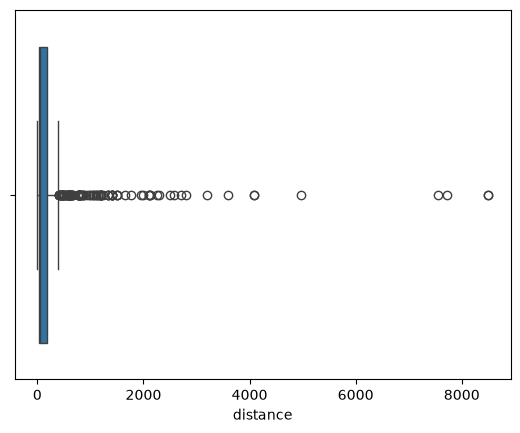

In [13]:
sns.boxplot(x='distance', data= planets)

In [ ]:
#la metrica distance è molto eterogenea. per ridurre la varianza possiamo descivere la variabile allinterno di ciascun gruppo.
#Quinid raggruppiao il datarfame per Method e vediamo la distribuzione di Distance.

<Axes: xlabel='distance', ylabel='method'>

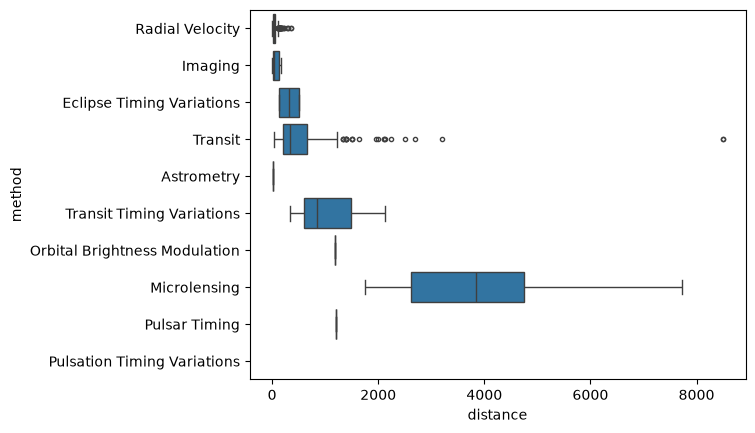

In [ ]:
sns.boxplot(x = 'distance', y = 'method', data = planets, fliersize=3, linewidth=1)
#ok ora ho scomposto il dataframe in Method. e visto la variabile Distance per ognuno di loro e allora?
posso dire che Miceolensing è il metodo più potente in quanto è quelo che identifica pienati più distanti

<Axes: xlabel='distance', ylabel='method'>

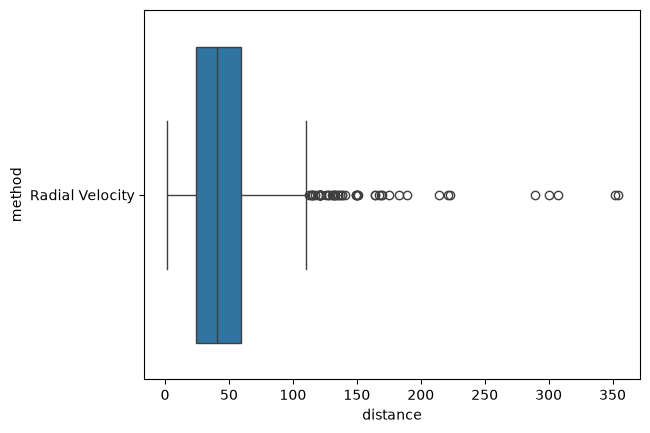

In [17]:
sns.boxplot(x='distance', y='method', data = planets[planets.method=='Radial Velocity'] )

<Axes: xlabel='distance', ylabel='method'>

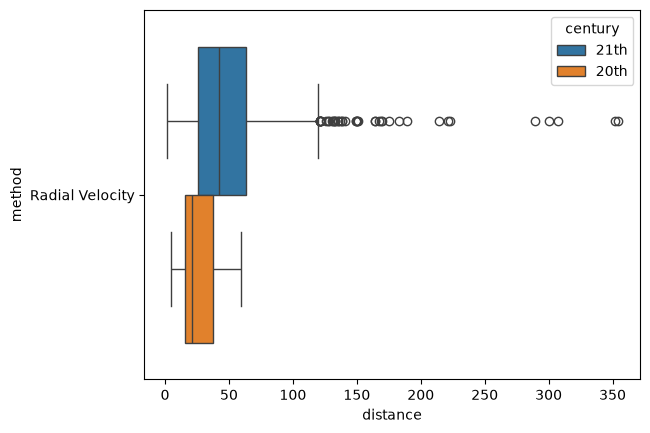

In [ ]:
#mi divide le osservazioni pe che secolo sono state fatte.
planets['century'] = ['20th' if el < 2000 else '21th' for el in planets.year]
#qui gurda alla distanza delle ossergazioni fatte che RADIAL velocity e ne fa la differenza tra 2 secoli.
# le osservazinoi fatte nel 21 secolo sono più disstanti.
sns.boxplot(x = 'distance', y = 'method', hue = 'century', data = planets[planets.method=='Radial Velocity'])

In [21]:
planets['jupiters'] = ['up to a Jupiter' if i <= 1 else 'More than 1' for i in planets['mass']]
planets.head(5)

,method,number,orbital_period,mass,distance,year,century,jupiters
0,Radial Velocity,1,269.300,7.10,77.40,2006,21th,More than 1
1,Radial Velocity,1,874.774,2.21,56.95,2008,21th,More than 1
2,Radial Velocity,1,763.000,2.60,19.84,2011,21th,More than 1
3,Radial Velocity,1,326.030,19.40,110.62,2007,21th,More than 1
4,Radial Velocity,1,516.220,10.50,119.47,2009,21th,More than 1


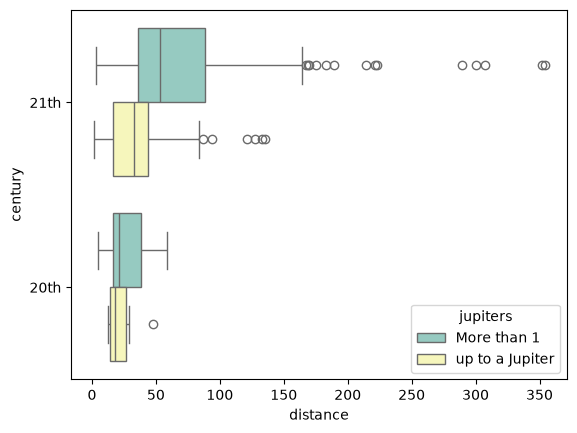

In [26]:
sns.boxplot(x = 'distance', y = 'century', hue = 'jupiters',data = planets[planets.method=='Radial Velocity'], palette="Set3");

In [27]:
peng = sns.load_dataset('penguins')
peng.head(3)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female


<Axes: xlabel='bill_length_mm', ylabel='Count'>

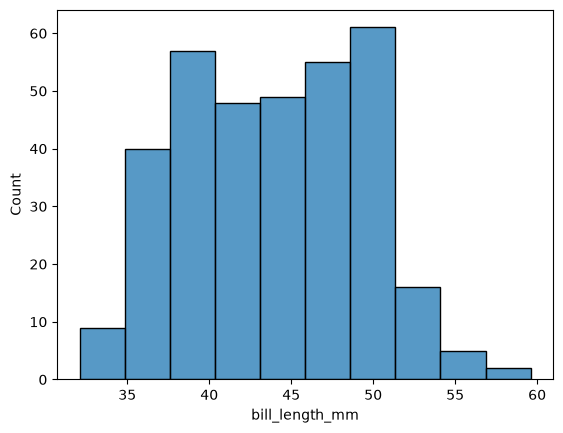

In [32]:
sns.histplot(x='bill_length_mm', data=peng, bins=10)
#qui vediamo le dimensioni di Bill organizzate in bins. e il numero di osservazioni per ognuna.

<Axes: xlabel='bill_length_mm', ylabel='Density'>

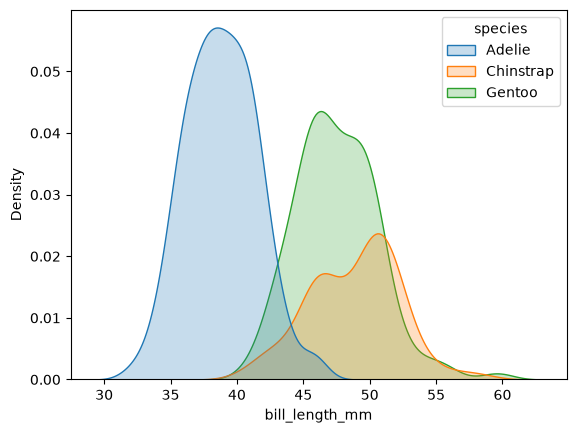

In [ ]:
sns.kdeplot(x = 'bill_length_mm', data = peng, hue = 'species', fill = True)
#una dimensione, lunghezza bill, vista per nelel tre species.
#questo mi dice visivamente qual'è la media di ogni specie. non devo scoprire nulla di più non c'è previsione qui.
#ora so che per specie A la media è tot e vedo che è rappresentativa. poi per species B so che la media è tot ed è rappresentativa.


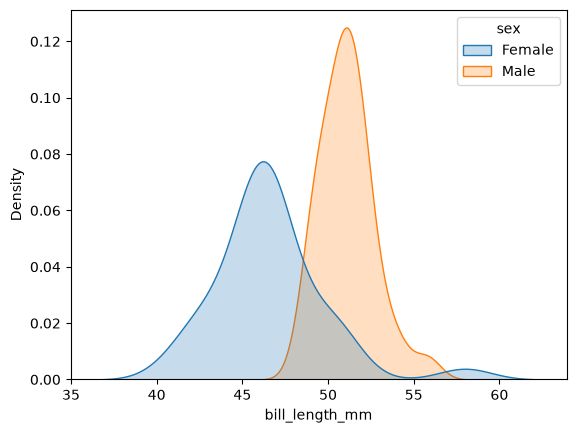

In [40]:
sns.kdeplot(x = 'bill_length_mm', data = peng[peng.species=='Chinstrap'], hue = 'sex', fill = True);

### Relazione tra due variabili

<Axes: xlabel='bill_length_mm', ylabel='bill_depth_mm'>

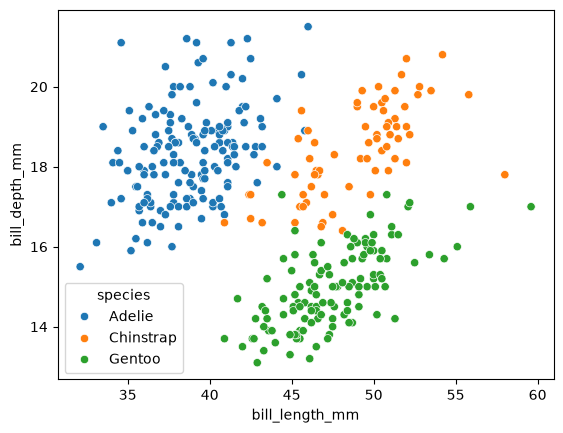

In [ ]:
sns.scatterplot(x='bill_length_mm', y='bill_depth_mm', data=peng, hue='species')
# mm non so bene cosa mi dica questo però...

La correlazione può avere una forza e una direzione.<br>
ad esempio lui guarda la correlazione tra length e depth del becco. su tutto il campione. <br>
facendo peng['bill_length_mm'].corr(peng['bill_depth_mm']) gli viene fuori -0,2 bassa e negativa.<br>
perché nella nuvola sopra nel complesso si abbassa.<br>

Poi però ricalcola la correlazione per ogni specie e come nel grafico ssi vede che è positiva e più forte

In [45]:
for spec in peng['species'].unique():
    cor = peng[peng.species==spec]['bill_length_mm'].corr(peng[peng.species==spec]['bill_depth_mm'])
    print(spec, '-->',round(cor,2))

Adelie --> 0.39
Chinstrap --> 0.65
Gentoo --> 0.64


Esploraimo visivamente la relazione tra le variabili. con il parametro HUE= possiamo evidenziare come i dati sono raggrupapti per una variabile categorica.

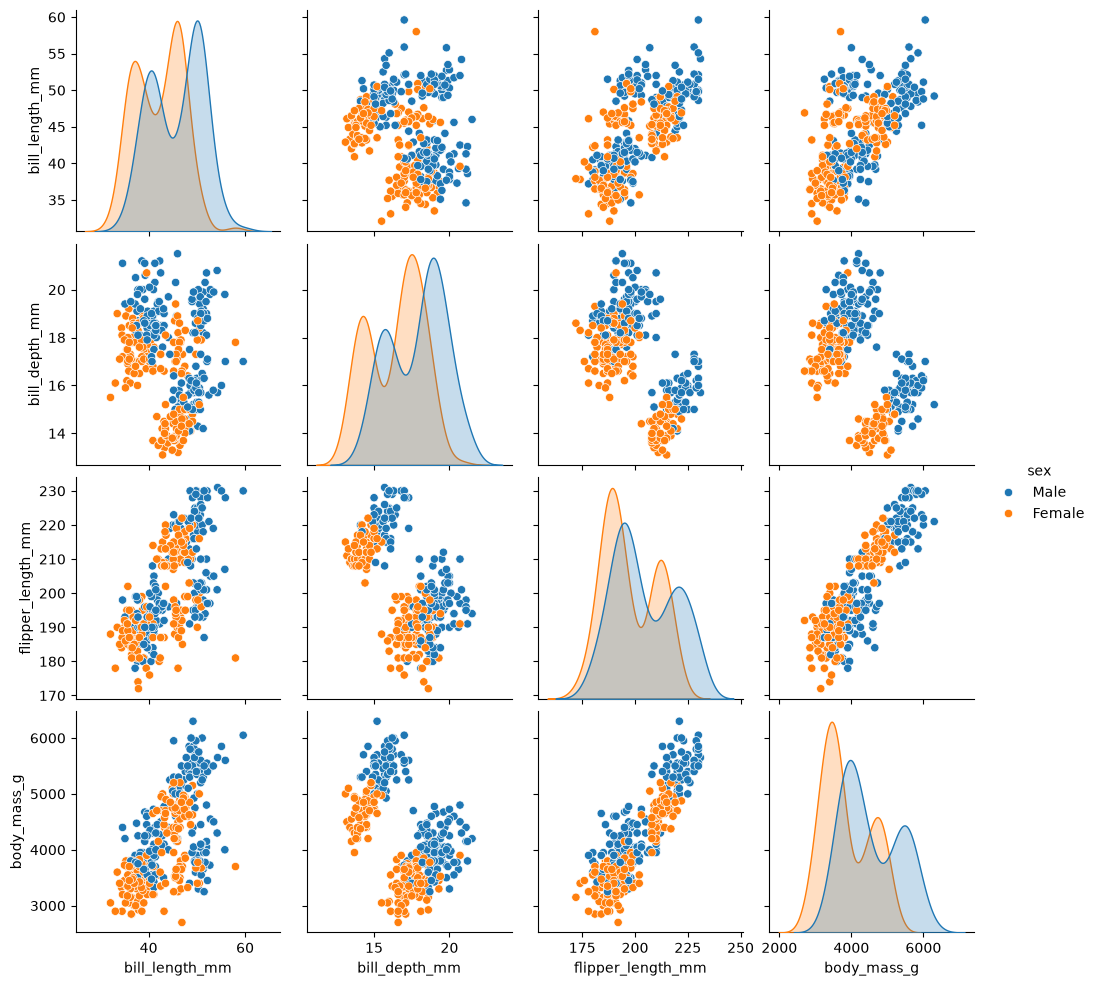

In [ ]:
sns.pairplot(peng, hue='sex');
#bodyMass+flipperLength sono molto correlate. Non sembrano esserci divisioni di sotto categorie
#bodyMaxx+billDepth invece ha due gruppi.

lo scatter mi suggerisce che relazione c'è tra due varaibili. visualizza quanto è forte e che direzione ha. Poi se voglio posso fare la regressione per determinare quale regola le collega.

